# 06 — Train, compare, explain, and evaluate next-week warnings

**Research protocol:**
1. Compare logistic regression, XGBoost, and LightGBM on three expanding-window folds inside 2025.
2. Relearn item support, numeric imputation, encoding, and class weights inside every fold.
3. Choose the model with highest mean fold **average precision (AP)**, a stepwise PR summary.
4. Fit on the final training period, choose its alert threshold by validation F1, then freeze it.
5. Evaluate the untouched test period against an always-no-surge baseline, a current-change rule,
   and the simpler logistic model. Do not select models using the final test table.

Fixed modest model settings keep this notebook understandable; this is not an exhaustive search
or proof of superiority over all forecasting systems. Pre-register any future tuning before a
new final holdout. No random row splitting, SMOTE across time, or test-based threshold selection.

Provisional criteria: **F1 ≥ 0.50 and AP ≥ 1.5 × event prevalence**. These are proposed research
criteria, not established stakeholder requirements or promised results. Report failures honestly
and justify operational costs of missed warnings versus false alerts in the dissertation.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Run from the repository root or its notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import numpy as np
import pricecatcher_config as cfg
from data_utils import save_json, surge_event
import json
import time
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
from data_utils import item_screen, time_masks, file_hash
from model_utils import model_inputs, make_model, metrics, choose_threshold, grouped_metrics, week_bootstrap
output = cfg.stage(6)
features_path = cfg.stage(5) / "features.parquet"
features = pd.read_parquet(features_path)
counts = pd.read_parquet(cfg.stage(2) / "item_daily_counts.parquet")
settings = json.loads((cfg.stage(5) / "experiment_settings.json").read_text())
expected = {"features": cfg.FEATURES, "surge_threshold_pct": cfg.SURGE_THRESHOLD_PCT,
    "minimum_records": cfg.MIN_RECORDS, "minimum_premises": cfg.MIN_PREMISES,
    "minimum_history_4w": cfg.MIN_HISTORY_4W, "train_end": cfg.TRAIN_END,
    "validation_end": cfg.VALIDATION_END}
if any(settings[key] != value for key, value in expected.items()):
    raise ValueError("Configuration changed since Notebook 05. Rerun notebooks 01–05 as appropriate.")
model_names = ["LogisticRegression", "XGBoost", "LightGBM"]

def supported_split(train_end, evaluation_end):
    screen = item_screen(counts, train_end)
    supported = screen.loc[screen["include"], "item_code"]
    train_mask, evaluation_mask = time_masks(features, train_end, evaluation_end)
    training = features.loc[train_mask & features["item_code"].isin(supported)].copy()
    evaluation = features.loc[evaluation_mask & features["item_code"].isin(supported)].copy()
    return training, evaluation, screen


## 1. Expanding-window model comparison
All districts from a prediction week stay together. Earlier observed prices can support later
features, as they would in weekly deployment. A validation week's target is never available
at that week's prediction time. Diagnostic outlier flags do not influence these models or labels.
Folds without two training classes or positive evaluation cases cannot support AP comparison.

In [2]:
cv_rows, cv_screens = [], []
for fold, (train_end, evaluation_end) in enumerate(cfg.CV_WINDOWS, start=1):
    if pd.Timestamp(evaluation_end) > pd.Timestamp(cfg.TRAIN_END):
        raise ValueError("Backtesting must remain inside the final training period.")
    training, evaluation, screen = supported_split(train_end, evaluation_end)
    if training.empty or evaluation.empty or training["surge_label"].nunique() < 2 or evaluation["surge_label"].sum() == 0:
        raise ValueError(f"Fold {fold} has insufficient supported data/classes. Redesign and document folds before testing.")
    assert training["next_week_end"].max() < evaluation["week_end"].min()
    X_train, X_evaluation = model_inputs(training), model_inputs(evaluation)
    y_train, y_evaluation = training["surge_label"].astype(int), evaluation["surge_label"].astype(int)
    screen["fold"], screen["training_end"] = fold, train_end
    cv_screens.append(screen)
    for name in model_names:
        started = time.perf_counter()
        pipeline = make_model(name, y_train)
        pipeline.fit(X_train, y_train)
        probability = pipeline.predict_proba(X_evaluation)[:, 1]
        row = {"fold": fold, "model": name, "train_end": train_end, "evaluation_end": evaluation_end,
               "training_rows": len(training), "fit_and_predict_seconds": time.perf_counter() - started}
        row.update(metrics(y_evaluation, probability))
        cv_rows.append(row)
        print("Fold", fold, name, "AP:", round(row["average_precision"], 4))
    # Fixed transparent rules have no fitted preprocessing or tuned alert cutoff.
    for name, probability in [
        ("AlwaysNoSurge", np.zeros(len(evaluation))),
        ("CurrentChangeRule", surge_event(evaluation["weekly_price_change_pct"]).astype(float).to_numpy()),
    ]:
        row = {"fold": fold, "model": name, "train_end": train_end, "evaluation_end": evaluation_end,
               "training_rows": len(training), "fit_and_predict_seconds": 0.0}
        row.update(metrics(y_evaluation, probability))
        cv_rows.append(row)
cv = pd.DataFrame(cv_rows)
cv.to_csv(output / "expanding_window_results.csv", index=False)
pd.concat(cv_screens, ignore_index=True).to_csv(output / "fold_item_screens.csv", index=False)
leaderboard = cv.groupby("model").agg(mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_f1_at_0_5=("f1", "mean"), folds=("fold", "nunique")).sort_values("mean_ap", ascending=False)
leaderboard.to_csv(output / "cv_leaderboard.csv")
selected_name = leaderboard.loc[leaderboard.index.isin(model_names)].index[0]
print("Selected using backtests only:", selected_name)
display(leaderboard)


Fold 1 LogisticRegression AP: 0.3076
Fold 1 XGBoost AP: 0.2735
Fold 1 LightGBM AP: 0.2716
Fold 2 LogisticRegression AP: 0.3321
Fold 2 XGBoost AP: 0.3971
Fold 2 LightGBM AP: 0.3906
Fold 3 LogisticRegression AP: 0.3082
Fold 3 XGBoost AP: 0.3537
Fold 3 LightGBM AP: 0.3585
Selected using backtests only: XGBoost


,mean_ap,std_ap,mean_f1_at_0_5,folds
model,,,,
XGBoost,0.341435,0.062698,0.386508,3
LightGBM,0.340237,0.061563,0.389703,3
LogisticRegression,0.315966,0.013934,0.355317,3
CurrentChangeRule,0.138364,0.038920,0.173589,3
AlwaysNoSurge,0.127037,0.023372,0.000000,3


## 2. Final training and validation-only alert thresholds
Each candidate is trained only through 2025. Validation outcomes choose an F1 alert cutoff.
The selected model identity remains the backtest winner even if another candidate happens
to score better on validation or test. Class weighting changes score calibration: call these
model scores, not proven calibrated probabilities. Persist the complete preprocessing pipeline.

In [3]:
training, validation, final_screen = supported_split(cfg.TRAIN_END, cfg.VALIDATION_END)
final_screen.to_csv(output / "final_item_screen.csv", index=False)
X_train, X_validation = model_inputs(training), model_inputs(validation)
y_train, y_validation = training["surge_label"].astype(int), validation["surge_label"].astype(int)
models, thresholds, validation_rows = {}, {}, []
for name in model_names:
    pipeline = make_model(name, y_train)
    pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_validation)[:, 1]
    threshold = choose_threshold(y_validation, probability)
    models[name], thresholds[name] = pipeline, threshold
    row = {"model": name}
    row.update(metrics(y_validation, probability, threshold))
    validation_rows.append(row)
pd.DataFrame(validation_rows).to_csv(output / "validation_results.csv", index=False)
display(pd.DataFrame(validation_rows))
selected = models[selected_name]
alert_threshold = thresholds[selected_name]
joblib.dump(selected, output / "selected_pipeline.joblib")
# Only load joblib files you trust; they are executable Python serialisations.
save_json(output / "model_selection.json", {
    "selected_model": selected_name, "selection_rule": "highest mean expanding-window AP",
    "threshold_rule": "maximum validation F1, higher cutoff on ties", "alert_threshold": alert_threshold,
    "trained_through": cfg.TRAIN_END, "validation_through": cfg.VALIDATION_END,
    "feature_file_sha256": file_hash(features_path), "feature_columns": cfg.FEATURES,
    "supported_item_codes": [int(x) for x in final_screen.loc[final_screen["include"], "item_code"]],
    "seed": cfg.SEED, "target_f1": cfg.TARGET_F1, "target_ap_lift": cfg.TARGET_AP_LIFT,
})


,model,rows,positives,prevalence,average_precision,ap_lift,precision,recall,f1,alerts,threshold
0,LogisticRegression,50821,5014,0.09866,0.240141,2.434022,0.246600,0.549661,0.340457,11176,0.634395
1,XGBoost,50821,5014,0.09866,0.231729,2.348761,0.231102,0.565217,0.328066,12263,0.645399
2,LightGBM,50821,5014,0.09866,0.230013,2.331366,0.226006,0.618069,0.330984,13712,0.619682


## 3. Final test — evaluate once after freezing choices
Test records must have observed supported outcomes; live forecasts do not require those future
observations. Report this retrospective evaluation population explicitly. AP is undefined for
subgroups with no positives; precision/recall/F1 use zero for zero denominators and support
counts show why. A high overall score cannot establish reliable sugar/oil warnings.

,model,selected_by_cv,rows,positives,prevalence,average_precision,ap_lift,precision,recall,f1,alerts,threshold
0,LogisticRegression,False,62516,9009,0.144107,0.299715,2.079805,0.330497,0.357864,0.343637,9755,0.634395
1,XGBoost,True,62516,9009,0.144107,0.332256,2.305615,0.344745,0.350982,0.347836,9172,0.645399
2,LightGBM,False,62516,9009,0.144107,0.328174,2.277290,0.336865,0.409368,0.369595,10948,0.619682
3,AlwaysNoSurge,False,62516,9009,0.144107,0.144107,1.000000,0.000000,0.000000,0.000000,0,0.500000
4,CurrentChangeRule,False,62516,9009,0.144107,0.160581,1.114314,0.218647,0.221001,0.219818,9106,0.500000


,average_precision,f1,precision,recall
0.025,0.298376,0.333293,0.299444,0.311882
0.975,0.376316,0.359438,0.406913,0.394155


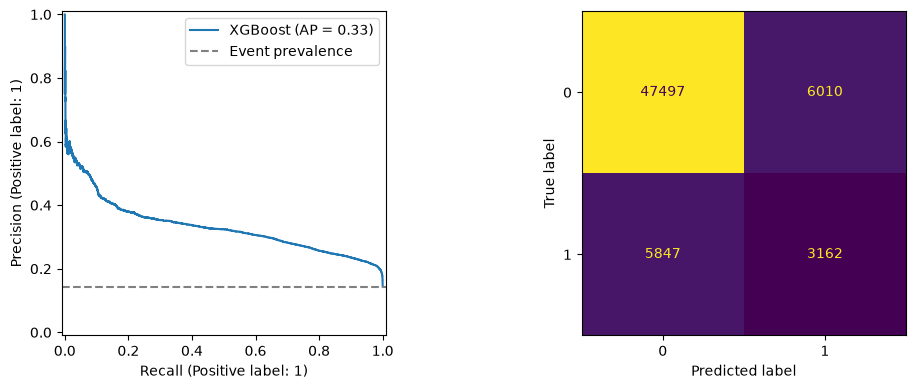

In [4]:
_, test_mask = time_masks(features, cfg.VALIDATION_END, pd.Period(cfg.END_MONTH).end_time)
supported_codes = final_screen.loc[final_screen["include"], "item_code"]
test = features.loc[test_mask & features["item_code"].isin(supported_codes)].copy()
if test.empty:
    raise ValueError("No supported final test rows.")
X_test, y_test = model_inputs(test), test["surge_label"].astype(int)
test_rows, test_probabilities = [], {}
for name, pipeline in models.items():
    probability = pipeline.predict_proba(X_test)[:, 1]
    test_probabilities[name] = probability
    row = {"model": name, "selected_by_cv": name == selected_name}
    row.update(metrics(y_test, probability, thresholds[name]))
    test_rows.append(row)
for name, probability in [
    ("AlwaysNoSurge", np.zeros(len(test))),
    ("CurrentChangeRule", surge_event(test["weekly_price_change_pct"]).astype(float).to_numpy()),
]:
    row = {"model": name, "selected_by_cv": False}
    row.update(metrics(y_test, probability))
    test_rows.append(row)
test_results = pd.DataFrame(test_rows)
test_results.to_csv(output / "test_results.csv", index=False)
display(test_results)
probability = test_probabilities[selected_name]
predictions = test[cfg.SERIES_KEYS + ["project_group", "week_start", "next_week_end", "surge_label"]].copy()
predictions["score"] = probability
predictions["alert"] = probability >= alert_threshold
predictions.to_parquet(output / "test_predictions.parquet", index=False)
for label, columns in [("food_group", ["project_group"]), ("state", ["state"]), ("district", ["state", "district"])]:
    grouped_metrics(test, probability, alert_threshold, columns).to_csv(output / f"test_metrics_by_{label}.csv", index=False)
intervals = week_bootstrap(test, probability, alert_threshold)
intervals.to_csv(output / "test_week_bootstrap_intervals.csv")
display(intervals)
selected_result = test_results.loc[test_results["selected_by_cv"]].iloc[0]
save_json(output / "research_criteria.json", {
    "criteria_status": "provisional research criteria; justify operationally in the report",
    "target_f1": cfg.TARGET_F1, "target_ap_lift": cfg.TARGET_AP_LIFT,
    "f1_met": bool(selected_result["f1"] >= cfg.TARGET_F1),
    "ap_lift_met": bool(selected_result["ap_lift"] >= cfg.TARGET_AP_LIFT),
    "test_weeks": int(test["week_start"].nunique()),
    "warning": "No claim of affordability improvement, causal explanation, or superiority to all existing systems.",
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PrecisionRecallDisplay.from_predictions(y_test, probability, ax=axes[0], name=selected_name)
axes[0].axhline(y_test.mean(), linestyle="--", color="grey", label="Event prevalence")
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, probability >= alert_threshold, ax=axes[1], labels=[0, 1], colorbar=False)
fig.tight_layout(); fig.savefig(output / "test_evaluation.png", dpi=160); plt.show()


## 4. Separate unsupervised anomaly detection
Isolation Forest flags unusual feature combinations; it does not provide surge ground truth.
Fit only on training features. The fixed 1% contamination setting is a review-budget heuristic,
not an empirically established anomaly prevalence. No anomaly precision/recall is claimed without
independent anomaly labels. Keep its score and flag separate from the supervised warning.

In [5]:
from sklearn.ensemble import IsolationForest
anomaly_detector = IsolationForest(n_estimators=100, contamination=0.01,
    random_state=cfg.SEED, n_jobs=cfg.N_JOBS)
preprocessing = selected.named_steps["preprocess"]
anomaly_detector.fit(preprocessing.transform(X_train))
test_matrix = preprocessing.transform(X_test)
anomaly_results = test[cfg.SERIES_KEYS + ["week_start"]].copy()
anomaly_results["anomaly_score"] = -anomaly_detector.decision_function(test_matrix)
anomaly_results["is_anomaly"] = anomaly_detector.predict(test_matrix) == -1
anomaly_results.to_parquet(output / "test_anomaly_review.parquet", index=False)
joblib.dump({"preprocess": preprocessing, "detector": anomaly_detector}, output / "isolation_forest.joblib")


['/Users/alfredyap/Documents/GitHub/Food/outputs/06/isolation_forest.joblib']

## 5. Offline SHAP cache for current forecasts
Precompute explanations for up to 200 supported series in the **latest global week**, ordered
by warning score. A dashboard reads cached forecasts/explanations rather than recomputing SHAP
per click. The cache explicitly marks rows without explanations. Measure serving latency in the
future dashboard; offline timings alone do not prove responsive UI behaviour.

SHAP contributions explain model log-odds, not causal drivers. One-hot contributions are grouped
back to the original feature names. External weather, fuel, imports, and exchange rates are
outside this model. This evaluation artifact is trained through 2025; it is not a scheduled,
continuously updated deployment.

In [6]:
import shap
latest_week = features["week_start"].max()
latest = features.loc[features["week_start"].eq(latest_week)
    & features["current_coverage_ok"] & features["history_ok"]
    & features["item_code"].isin(supported_codes)].copy()
if latest.empty:
    raise ValueError("No supported forecasts in the latest week; do not silently show stale weeks.")
started = time.perf_counter()
latest["score"] = selected.predict_proba(model_inputs(latest))[:, 1]
latest["alert"] = latest["score"] >= alert_threshold
latest_matrix = selected.named_steps["preprocess"].transform(model_inputs(latest))
latest["anomaly_score"] = -anomaly_detector.decision_function(latest_matrix)
latest["is_anomaly"] = anomaly_detector.predict(latest_matrix) == -1
latest = latest.sort_values("score", ascending=False).reset_index(drop=True)
latest["forecast_id"] = np.arange(len(latest))
cache_rows = latest.head(200)
preprocessing, estimator = selected.named_steps["preprocess"], selected.named_steps["model"]
transformed = preprocessing.transform(model_inputs(cache_rows))
matrix = transformed.toarray() if hasattr(transformed, "toarray") else np.asarray(transformed)
if selected_name == "LogisticRegression":
    background = preprocessing.transform(X_train.sample(min(100, len(X_train)), random_state=cfg.SEED))
    background = background.toarray() if hasattr(background, "toarray") else background
    explainer = shap.LinearExplainer(estimator, background)
    raw_scores = estimator.decision_function(matrix)
elif selected_name == "XGBoost":
    explainer = shap.TreeExplainer(estimator)
    raw_scores = estimator.predict(matrix, output_margin=True)
else:
    explainer = shap.TreeExplainer(estimator)
    raw_scores = estimator.predict(matrix, raw_score=True)
explanation = explainer(matrix)
values, base = np.asarray(explanation.values), np.asarray(explanation.base_values)
if values.ndim == 3:
    values = values[:, :, 1]
    base = base[:, 1]
base = np.broadcast_to(np.squeeze(base), (len(cache_rows),))
np.testing.assert_allclose(base + values.sum(axis=1), raw_scores, rtol=1e-3, atol=1e-3)

# Numeric missing-indicator columns are grouped with the original numeric feature.
numeric_names = preprocessing.named_transformers_["numeric"].named_steps["imputer"].get_feature_names_out(cfg.NUM_FEATURES)
source_names = [str(x).replace("missingindicator_", "") for x in numeric_names]
encoder = preprocessing.named_transformers_["category"]
for column, categories in zip(cfg.CAT_FEATURES, encoder.categories_):
    source_names.extend([column] * len(categories))
assert len(source_names) == values.shape[1]
explanation_rows = []
for position, (_, row) in enumerate(cache_rows.iterrows()):
    contributions = pd.Series(values[position]).groupby(source_names, sort=False).sum()
    top = contributions.abs().nlargest(5).index
    explanation_rows.append({"forecast_id": int(row["forecast_id"]),
        "base_log_odds": float(base[position]), "model_log_odds": float(raw_scores[position]),
        "top_features": [{"feature": feature, "contribution_log_odds": float(contributions[feature])} for feature in top]})
explained_ids = set(cache_rows["forecast_id"])
latest["has_cached_explanation"] = latest["forecast_id"].isin(explained_ids)
latest[cfg.SERIES_KEYS + ["item", "unit", "project_group", "week_start", "forecast_id", "score", "alert", "anomaly_score", "is_anomaly", "has_cached_explanation"]].to_parquet(output / "latest_forecasts.parquet", index=False)
save_json(output / "shap_cache.json", explanation_rows)
save_json(output / "explanation_timing.json", {
    "latest_week": str(latest_week.date()), "forecast_rows": len(latest), "explained_rows": len(cache_rows),
    "offline_forecast_and_explanation_seconds": time.perf_counter() - started,
    "cache_policy": "top 200 scores per batch; dashboard reads cache; remaining rows marked unavailable",
    "contribution_units": "log-odds; associational model explanation, not causal attribution",
})
# Verify saved pipelines reproduce the selected model's scores.
reloaded = joblib.load(output / "selected_pipeline.joblib")
np.testing.assert_allclose(reloaded.predict_proba(X_test.iloc[:100])[:, 1], probability[:100])
print("Saved model, evaluations, forecasts, and SHAP cache to", output)


ModuleNotFoundError: No module named 'shap'

## Interpretation and remaining FYP work
- Report the selected model even when another test model scores higher. Do not rewrite the selection rule after testing.
- Report unstable fold scores, few positive cases, and excluded districts; no positives means no demonstrated surge-learning ability.
- Compare aggregation sensitivities from Notebook 05 before describing warnings as actual within-shop price inflation.
- Bootstrap intervals resample weeks within one short test period. They do not establish robustness across years or new policy regimes.
- Isolation Forest flags are saved separately for manual review. Independent anomaly labels are needed to evaluate anomaly detection accuracy.
- A future dashboard and stakeholder study are needed to establish usability, warning usefulness, and affordability outcomes.
